# Week 15 — EEGNet Interpretability

## Goal

Investigate which parts of validation EEG trials influence predictions from the frozen Configuration D EEGNet.

Initial methods:

1. Input-gradient saliency
2. Channel-level and temporal summaries
3. Occlusion

### Imports and paths

In [56]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import mne
from mne.datasets import eegbci

In [79]:
ROOT = Path.cwd().parent

sys.path.insert(
    0,
    str(ROOT / "src")
)

from neurosignallab.inference import (
    load_eegnet,
    predict_trial
)

from neurosignallab.models import EEGNet

CHECKPOINT_PATH = (
    ROOT
    / "models"
    / "config_d_seed42_best.pt"
)

SPLIT_PATH = (
    ROOT
    / "results"
    / "week9_subject_split.csv"
)

DATA_PATH = (
    ROOT
    / "data"
    / "processed"
)

### Load pre-trained configuration D 

In [5]:
model, checkpoint, device = load_eegnet(
    CHECKPOINT_PATH
)

print("Device:", device)
print("Model:", checkpoint["model_name"])
print("Best epoch:", checkpoint["best_epoch"])
print(
    "Validation BA:",
    checkpoint["validation_balanced_accuracy"]
)

Device: mps
Model: EEGNet_Config_D
Best epoch: 19
Validation BA: 0.6277011922503726


### Load validation data

In [6]:
split_df = pd.read_csv(SPLIT_PATH)

validation_subjects = split_df.loc[
    split_df["split"] == "validation",
    "subject"
].to_numpy()


subjects = np.load(
    DATA_PATH / "subjects.npy"
)

validation_mask = np.isin(
    subjects,
    validation_subjects
)


X_val = np.load(
    DATA_PATH / "X_motor_imagery.npy",
    mmap_mode="r"
)[validation_mask]

y_val = np.load(
    DATA_PATH / "y_motor_imagery.npy",
    mmap_mode="r"
)[validation_mask]

subjects_val = subjects[
    validation_mask
]

runs_val = np.load(
    DATA_PATH / "runs.npy",
    mmap_mode="r"
)[validation_mask]

In [7]:
print("X:", X_val.shape)
print("y:", y_val.shape)
print(
    "Validation subjects:",
    len(np.unique(subjects_val))
)

X: (718, 64, 481)
y: (718,)
Validation subjects: 16


### One trial inference

In [8]:
trial_index = 0

trial = X_val[trial_index]
true_label = int(y_val[trial_index])

result = predict_trial(
    model,
    trial,
    checkpoint,
    device
)

/Users/heihei/Desktop/neurosignallab/.venv/lib/python3.13/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv2d(


In [9]:
print(
    "Subject:",
    subjects_val[trial_index]
)

print(
    "True class:",
    checkpoint["class_names"][true_label]
)

print(
    "Predicted class:",
    result["predicted_class"]
)

print(
    "Model output:",
    result["probabilities"]
)

Subject: 1
True class: imagined right fist
Predicted class: imagined left fist
Model output: [0.53846186 0.46153814]


### Make forward pass calculate all gradients

In [10]:
target_class = result["prediction"]

x = torch.tensor(
    trial,
    dtype=torch.float32,
    device=device
)

x = x * checkpoint["input_multiplier"]

x = x.unsqueeze(0)
x = x.unsqueeze(0)

x.requires_grad_(True)

tensor([[[[-16.0791, -18.8293,  -5.5376,  ...,  -9.9723,  -7.0415,  -3.2630],
          [ -4.2704, -13.5483, -11.1732,  ..., -13.5982,  -3.4923,   0.8874],
          [  5.9556,  -2.6708,  -5.3980,  ..., -16.7783,  -7.6369,   0.0508],
          ...,
          [ -9.5896,  11.8353,  28.9222,  ...,  20.7437,  11.8667,  -0.9663],
          [-28.6266,   5.2302,  36.7334,  ...,  13.9888,  13.3928,   0.0625],
          [ -5.9619,  16.7760,  33.0263,  ...,  20.5558,  11.2200,   3.7421]]]],
       device='mps:0', requires_grad=True)

### Forward pass

In [11]:
model.zero_grad()

logits = model(x)

target_logit = logits[
    0,
    target_class
]

### Calculate gradients, where model is sensitive to input

In [12]:
target_logit.backward()

gradients = (
    x.grad
    .detach()
    .squeeze(0)
    .squeeze(0)
    .cpu()
    .numpy()
)

### Check saliency, where is model most sensitive?

In [13]:
saliency = np.abs(gradients)

print("Gradient shape:", gradients.shape)
print("Saliency shape:", saliency.shape)

Gradient shape: (64, 481)
Saliency shape: (64, 481)


In [14]:
manual_probabilities = (
    torch.softmax(
        logits,
        dim=1
    )
    .detach()
    .cpu()
    .numpy()[0]
)

print(
    "predict_trial():",
    result["probabilities"]
)

print(
    "manual forward:",
    manual_probabilities
)

print(
    "Match:",
    np.allclose(
        result["probabilities"],
        manual_probabilities
    )
)

predict_trial(): [0.53846186 0.46153814]
manual forward: [0.53846186 0.46153814]
Match: True


### Channel x time heatmap

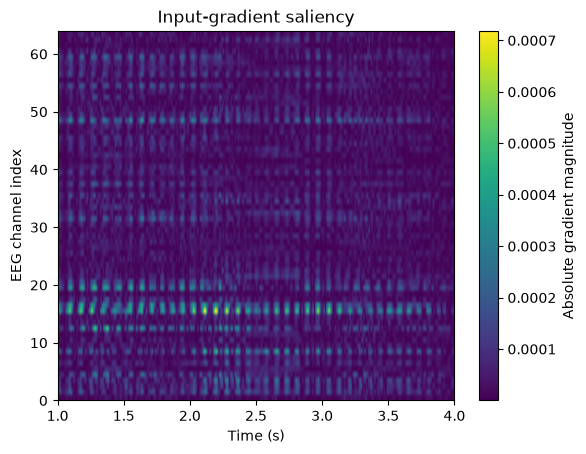

In [15]:
time = (
    np.arange(saliency.shape[1])
    / checkpoint["sampling_rate_hz"]
    + 1.0
)

fig, ax = plt.subplots()

image = ax.imshow( #Treat matrix as image
    saliency,
    aspect="auto",
    origin="lower",
    extent=[
        time[0],
        time[-1],
        0,
        saliency.shape[0]
    ]
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("EEG channel index")
ax.set_title("Input-gradient saliency")

fig.colorbar(
    image,
    ax=ax,
    label="Absolute gradient magnitude"
)

plt.show()

### Average saliency per channel

In [16]:
channel_saliency = saliency.mean(
    axis=1
)

print(
    "Channel saliency shape:",
    channel_saliency.shape
)

Channel saliency shape: (64,)


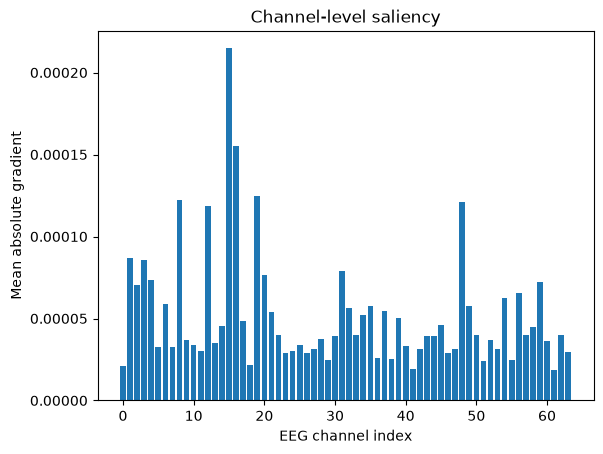

In [17]:
fig, ax = plt.subplots()

ax.bar(
    np.arange(len(channel_saliency)),
    channel_saliency
)

ax.set_xlabel("EEG channel index")
ax.set_ylabel("Mean absolute gradient")
ax.set_title("Channel-level saliency")

plt.show()

### Check strongest channels

In [18]:
top_channels = np.argsort(
    channel_saliency
)[::-1][:10]

print(
    "Top 10 channel indices:",
    top_channels
)

print(
    "Top 10 channel saliency:",
    channel_saliency[top_channels]
)

Top 10 channel indices: [15 16 19  8 48 12  1  3 31 20]
Top 10 channel saliency: [2.1465858e-04 1.5528261e-04 1.2478841e-04 1.2251960e-04 1.2113348e-04
 1.1860775e-04 8.7199616e-05 8.5564250e-05 7.9037571e-05 7.6430988e-05]


### Temporal saliency

In [19]:
temporal_saliency = saliency.mean(
    axis=0
)

print(
    "Temporal saliency shape:",
    temporal_saliency.shape
)

Temporal saliency shape: (481,)


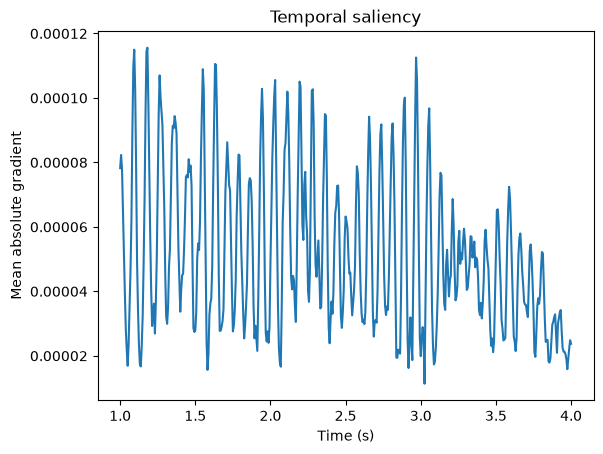

In [20]:
fig, ax = plt.subplots()

ax.plot(
    time,
    temporal_saliency
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Mean absolute gradient")
ax.set_title("Temporal saliency")

plt.show()

### Channel occlusion

In [21]:
target_class = result["prediction"]
original_target_logit = result["logits"][target_class]

channel_occlusion = np.zeros(
    trial.shape[0]
)

for channel in range(trial.shape[0]):
    occluded_trial = trial.copy()

    occluded_trial[channel] = 0.0

    occluded_result = predict_trial(
        model,
        occluded_trial,
        checkpoint,
        device
    )

    occluded_target_logit = (
        occluded_result["logits"][target_class]
    )

    channel_occlusion[channel] = (
        original_target_logit
        - occluded_target_logit
    )

### Plot occlusion

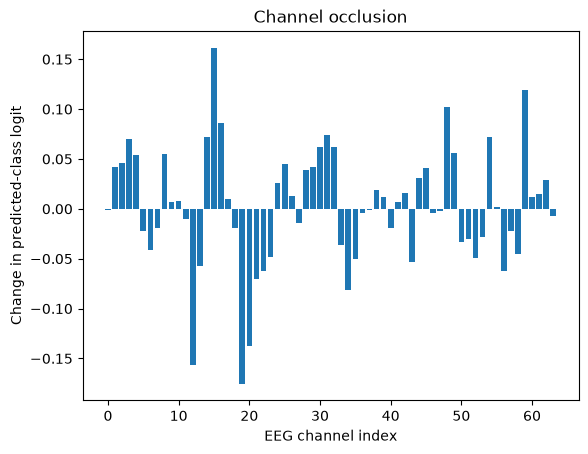

In [22]:
fig, ax = plt.subplots()

ax.bar(
    np.arange(len(channel_occlusion)),
    channel_occlusion
)

ax.set_xlabel("EEG channel index")
ax.set_ylabel("Change in predicted-class logit")
ax.set_title("Channel occlusion")

plt.show()

### See best results

In [23]:
top_occlusion_channels = np.argsort(
    channel_occlusion
)[::-1][:10]

print(
    "Top 10 occlusion channels:",
    top_occlusion_channels
)

print(
    "Top 10 occlusion effects:",
    channel_occlusion[top_occlusion_channels]
)

Top 10 occlusion channels: [15 59 48 16 31 14 54  3 32 30]
Top 10 occlusion effects: [0.16154981 0.11866794 0.10163248 0.08633517 0.07430135 0.07221615
 0.07206881 0.06983872 0.06235221 0.06212798]


### Temporal occlusion

In [24]:
window_size = 40 # remove 250ms windows
sampling_rate = checkpoint["sampling_rate_hz"]

window_starts = range(
    0,
    trial.shape[1],
    window_size
)

temporal_occlusion = []
window_times = []

for start in window_starts:
    end = min(
        start + window_size,
        trial.shape[1]
    )

    occluded_trial = trial.copy()

    occluded_trial[:, start:end] = 0.0

    occluded_result = predict_trial(
        model,
        occluded_trial,
        checkpoint,
        device
    )

    occluded_target_logit = (
        occluded_result["logits"][target_class]
    )

    effect = (
        original_target_logit
        - occluded_target_logit
    )

    temporal_occlusion.append(effect)

    center_sample = (start + end) / 2

    center_time = (
        center_sample / sampling_rate
        + 1.0
    )

    window_times.append(center_time)

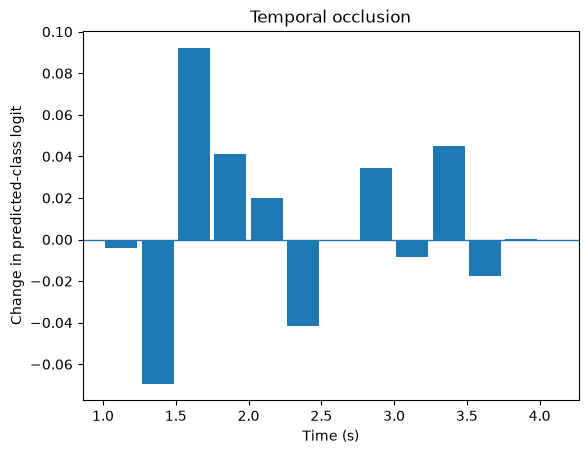

In [25]:
fig, ax = plt.subplots()

ax.bar(
    window_times,
    temporal_occlusion,
    width=0.22
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_xlabel("Time (s)")
ax.set_ylabel(
    "Change in predicted-class logit"
)
ax.set_title("Temporal occlusion")

plt.show()

## Make functions for multiple trials

### Saliency function

In [26]:
def compute_saliency(
    model,
    trial,
    checkpoint,
    device,
    target_class
):
    x = torch.tensor(
        trial,
        dtype=torch.float32,
        device=device
    )

    x = x * checkpoint["input_multiplier"]

    x = x.unsqueeze(0).unsqueeze(0)
    x.requires_grad_(True)

    model.zero_grad()

    logits = model(x)

    target_logit = logits[
        0,
        target_class
    ]

    target_logit.backward()

    gradients = (
        x.grad
        .detach()
        .squeeze()
        .cpu()
        .numpy()
    )

    return np.abs(gradients)

In [27]:
saliency_check = compute_saliency(
    model,
    trial,
    checkpoint,
    device,
    result["prediction"]
)

print(
    "Same result:",
    np.allclose(
        saliency,
        saliency_check
    )
)

Same result: True


### Occlusion function

In [28]:
def compute_channel_occlusion(
    model,
    trial,
    checkpoint,
    device,
    target_class
):
    original_result = predict_trial(
        model,
        trial,
        checkpoint,
        device
    )

    original_logit = (
        original_result["logits"][target_class]
    )

    effects = np.zeros(
        trial.shape[0]
    )

    for channel in range(trial.shape[0]):
        occluded_trial = trial.copy()
        occluded_trial[channel] = 0.0

        occluded_result = predict_trial(
            model,
            occluded_trial,
            checkpoint,
            device
        )

        occluded_logit = (
            occluded_result["logits"][target_class]
        )

        effects[channel] = (
            original_logit - occluded_logit
        )

    return effects

In [29]:
channel_occlusion_check = compute_channel_occlusion(
    model,
    trial,
    checkpoint,
    device,
    result["prediction"]
)

print(
    "Same channel occlusion:",
    np.allclose(
        channel_occlusion,
        channel_occlusion_check
    )
)

Same channel occlusion: True


### Temporal occlusion function

In [30]:
def compute_temporal_occlusion(
    model,
    trial,
    checkpoint,
    device,
    target_class,
    window_size=40
):
    original_result = predict_trial(
        model,
        trial,
        checkpoint,
        device
    )

    original_logit = (
        original_result["logits"][target_class]
    )

    effects = []
    window_centers = []

    sampling_rate = checkpoint[
        "sampling_rate_hz"
    ]

    for start in range(
        0,
        trial.shape[1],
        window_size
    ):
        end = min(
            start + window_size,
            trial.shape[1]
        )

        occluded_trial = trial.copy()
        occluded_trial[:, start:end] = 0.0

        occluded_result = predict_trial(
            model,
            occluded_trial,
            checkpoint,
            device
        )

        occluded_logit = (
            occluded_result["logits"][target_class]
        )

        effects.append(
            original_logit - occluded_logit
        )

        center_sample = (start + end) / 2

        center_time = (
            center_sample / sampling_rate
            + 1.0
        )

        window_centers.append(center_time)

    return (
        np.array(effects),
        np.array(window_centers)
    )

In [31]:
temporal_occlusion_check, window_times_check = (
    compute_temporal_occlusion(
        model,
        trial,
        checkpoint,
        device,
        result["prediction"]
    )
)

print(
    "Same temporal occlusion:",
    np.allclose(
        temporal_occlusion,
        temporal_occlusion_check
    )
)

print(
    "Same window times:",
    np.allclose(
        window_times,
        window_times_check
    )
)

Same temporal occlusion: True
Same window times: True


### Find different types of trials

In [38]:
examples = {}

for i in range(len(X_val)):
    trial_i = X_val[i]
    true_label = int(y_val[i])

    result_i = predict_trial(
        model,
        trial_i,
        checkpoint,
        device
    )

    predicted_label = result_i["prediction"]

    if true_label == 0 and predicted_label == 0:
        category = "correct_left"

    elif true_label == 1 and predicted_label == 1:
        category = "correct_right"

    elif true_label == 0 and predicted_label == 1:
        category = "left_misclassified"

    elif true_label == 1 and predicted_label == 0:
        category = "right_misclassified"

    else:
        continue

    if category not in examples:
        examples[category] = {
            "trial_index": i,
            "subject": int(subjects_val[i]),
            "run": int(runs_val[i]),
            "true_label": true_label,
            "result": result_i
        }

    if len(examples) == 4:
        break

In [40]:
for category, example in examples.items():
    result_i = example["result"]

    print(category)
    print("  trial_index:", example["trial_index"])
    print("  subject:", example["subject"])
    print("  run:", example["run"])
    print(
        "  true:",
        checkpoint["class_names"][
            example["true_label"]
        ]
    )
    print(
        "  predicted:",
        result_i["predicted_class"]
    )
    print(
        "  output:",
        result_i["probabilities"]
    )
    print()

right_misclassified
  trial_index: 0
  subject: 1
  run: 4
  true: imagined right fist
  predicted: imagined left fist
  output: [0.53846186 0.46153814]

correct_left
  trial_index: 1
  subject: 1
  run: 4
  true: imagined left fist
  predicted: imagined left fist
  output: [0.6520412  0.34795877]

correct_right
  trial_index: 3
  subject: 1
  run: 4
  true: imagined right fist
  predicted: imagined right fist
  output: [0.49576163 0.5042384 ]

left_misclassified
  trial_index: 10
  subject: 1
  run: 4
  true: imagined left fist
  predicted: imagined right fist
  output: [0.49742076 0.5025792 ]



### Find saliency and occulsion for the examples

In [41]:
interpretations = {}

for category, example in examples.items():
    i = example["trial_index"]
    trial_i = X_val[i]

    target_class = (
        example["result"]["prediction"]
    )

    saliency_i = compute_saliency(
        model,
        trial_i,
        checkpoint,
        device,
        target_class
    )

    channel_saliency_i = (
        saliency_i.mean(axis=1)
    )

    channel_occlusion_i = (
        compute_channel_occlusion(
            model,
            trial_i,
            checkpoint,
            device,
            target_class
        )
    )

    temporal_occlusion_i, window_times_i = (
        compute_temporal_occlusion(
            model,
            trial_i,
            checkpoint,
            device,
            target_class
        )
    )

    interpretations[category] = {
        "saliency": saliency_i,
        "channel_saliency": channel_saliency_i,
        "channel_occlusion": channel_occlusion_i,
        "temporal_occlusion": temporal_occlusion_i,
        "window_times": window_times_i
    }

### Find strongest channels

In [42]:
for category, interpretation in interpretations.items():

    top_saliency = np.argsort(
        interpretation["channel_saliency"]
    )[::-1][:5]

    top_occlusion = np.argsort(
        interpretation["channel_occlusion"]
    )[::-1][:5]

    print(category)

    print(
        "  Top saliency channels:",
        top_saliency
    )

    print(
        "  Top occlusion channels:",
        top_occlusion
    )

    print()

right_misclassified
  Top saliency channels: [15 16 19  8 48]
  Top occlusion channels: [15 59 48 16 31]

correct_left
  Top saliency channels: [15 16 19 48  8]
  Top occlusion channels: [15 60 16 62  4]

correct_right
  Top saliency channels: [15 19 16 12 48]
  Top occlusion channels: [12 19 20 34 52]

left_misclassified
  Top saliency channels: [15 19 16 12 48]
  Top occlusion channels: [19 12 20 56 35]



### Occlusion across subjects

In [43]:
predictions_val = np.zeros(
    len(X_val),
    dtype=int
)

for trial_index in range(len(X_val)):
    result_i = predict_trial(
        model,
        X_val[trial_index],
        checkpoint,
        device
    )

    predictions_val[trial_index] = (
        result_i["prediction"]
    )

### Select each validation subject, and 1 left and right trial from each

In [44]:
cross_subject_examples = []

for subject in np.unique(subjects_val):

    subject_indices = np.where(
        subjects_val == subject
    )[0]

    for predicted_label in [0, 1]:

        matching_indices = subject_indices[
            predictions_val[subject_indices]
            == predicted_label
        ]

        if len(matching_indices) > 0:
            trial_index = int(
                matching_indices[0]
            )

            cross_subject_examples.append(
                {
                    "subject": int(subject),
                    "trial_index": trial_index,
                    "predicted_label": predicted_label,
                    "true_label": int(
                        y_val[trial_index]
                    )
                }
            )

In [45]:
print(
    "Selected examples:",
    len(cross_subject_examples)
)

for example in cross_subject_examples[:6]:
    print(example)

Selected examples: 31
{'subject': 1, 'trial_index': 0, 'predicted_label': 0, 'true_label': 1}
{'subject': 1, 'trial_index': 3, 'predicted_label': 1, 'true_label': 1}
{'subject': 3, 'trial_index': 45, 'predicted_label': 0, 'true_label': 1}
{'subject': 3, 'trial_index': 58, 'predicted_label': 1, 'true_label': 0}
{'subject': 19, 'trial_index': 97, 'predicted_label': 0, 'true_label': 0}
{'subject': 19, 'trial_index': 90, 'predicted_label': 1, 'true_label': 1}


### Channel occlusion

In [46]:
cross_subject_results = []

for example in cross_subject_examples:

    trial_index = example["trial_index"]
    target_class = example["predicted_label"]

    effects = compute_channel_occlusion(
        model,
        X_val[trial_index],
        checkpoint,
        device,
        target_class
    )

    cross_subject_results.append(
        {
            **example,
            "channel_occlusion": effects
        }
    )

### Separate left and right predictions

In [47]:
left_occlusion = np.stack([
    item["channel_occlusion"]
    for item in cross_subject_results
    if item["predicted_label"] == 0
])

right_occlusion = np.stack([
    item["channel_occlusion"]
    for item in cross_subject_results
    if item["predicted_label"] == 1
])

In [48]:
print(
    "Left-predicted trials:",
    left_occlusion.shape
)

print(
    "Right-predicted trials:",
    right_occlusion.shape
)

Left-predicted trials: (16, 64)
Right-predicted trials: (15, 64)


### Average and strongest channels

In [50]:
mean_left_occlusion = (
    left_occlusion.mean(axis=0)
)

mean_right_occlusion = (
    right_occlusion.mean(axis=0)
)

In [51]:
top_left = np.argsort(
    mean_left_occlusion
)[::-1][:10]

top_right = np.argsort(
    mean_right_occlusion
)[::-1][:10]

print(
    "Top channels for predicted left:",
    top_left
)

print(
    "Top channels for predicted right:",
    top_right
)

print(
    "Left effects:",
    mean_left_occlusion[top_left]
)

print(
    "Right effects:",
    mean_right_occlusion[top_right]
)

Top channels for predicted left: [15 16 48  8  3 31 14 59  2  1]
Top channels for predicted right: [19 12 20 52 49 13 56 35 57 51]
Left effects: [0.1541503  0.06837065 0.06552475 0.0646419  0.04438733 0.04391912
 0.04256042 0.04057135 0.03924736 0.03234122]
Right effects: [0.19625922 0.1703469  0.10278857 0.07326166 0.05453364 0.0376626
 0.03615236 0.03417453 0.03232615 0.02603877]


### Plot

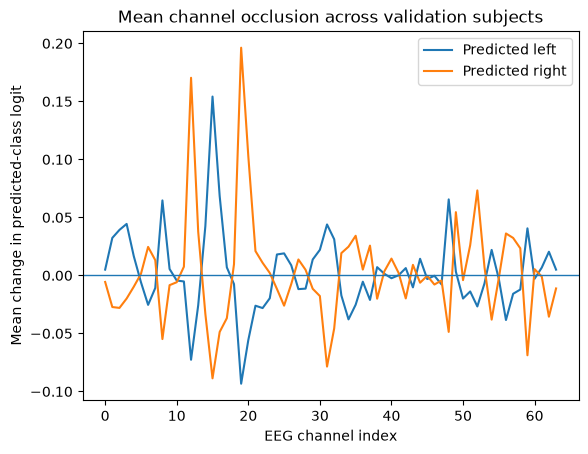

In [52]:
fig, ax = plt.subplots()

ax.plot(
    np.arange(64),
    mean_left_occlusion,
    label="Predicted left"
)

ax.plot(
    np.arange(64),
    mean_right_occlusion,
    label="Predicted right"
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_xlabel("EEG channel index")
ax.set_ylabel(
    "Mean change in predicted-class logit"
)
ax.set_title(
    "Mean channel occlusion across validation subjects"
)

ax.legend()

plt.show()

## Recover channel names

### Donwload one run from subject 1

In [57]:
raw_files = eegbci.load_data(
    1,
    runs=[4],
    path=ROOT / "data" / "raw" / "eegbci"
)

raw = mne.io.read_raw_edf(
    raw_files[0],
    preload=False,
    verbose=False
)

eegbci.standardize(raw)

Do you want to set the path:
    /Users/heihei/Desktop/neurosignallab/data/raw/eegbci
as the default EEGBCI dataset path in the mne-python config [y]/n?  y


### Print all channels

In [58]:
raw = mne.io.read_raw_edf(
    raw_files[0],
    preload=False,
    verbose=False
)

eegbci.standardize(raw)

channel_names = raw.ch_names

print("Number of channels:", len(channel_names))

for channel_index, channel_name in enumerate(channel_names):
    print(channel_index, channel_name)

Number of channels: 64
0 FC5
1 FC3
2 FC1
3 FCz
4 FC2
5 FC4
6 FC6
7 C5
8 C3
9 C1
10 Cz
11 C2
12 C4
13 C6
14 CP5
15 CP3
16 CP1
17 CPz
18 CP2
19 CP4
20 CP6
21 Fp1
22 Fpz
23 Fp2
24 AF7
25 AF3
26 AFz
27 AF4
28 AF8
29 F7
30 F5
31 F3
32 F1
33 Fz
34 F2
35 F4
36 F6
37 F8
38 FT7
39 FT8
40 T7
41 T8
42 T9
43 T10
44 TP7
45 TP8
46 P7
47 P5
48 P3
49 P1
50 Pz
51 P2
52 P4
53 P6
54 P8
55 PO7
56 PO3
57 POz
58 PO4
59 PO8
60 O1
61 Oz
62 O2
63 Iz


### Map notable channels

In [59]:
important_channels = [
    15, 16, 48, 8, 3, 31, 14, 59, 2, 1,
    19, 12, 20, 52, 49, 13, 56, 35, 57, 51
]

for channel_index in important_channels:
    print(
        channel_index,
        "→",
        channel_names[channel_index]
    )

15 → CP3
16 → CP1
48 → P3
8 → C3
3 → FCz
31 → F3
14 → CP5
59 → PO8
2 → FC1
1 → FC3
19 → CP4
12 → C4
20 → CP6
52 → P4
49 → P1
13 → C6
56 → PO3
35 → F4
57 → POz
51 → P2


In [60]:
print("Predicted LEFT")

for channel_index in top_left:
    print(
        channel_index,
        "→",
        channel_names[channel_index],
        mean_left_occlusion[channel_index]
    )


print("\nPredicted RIGHT")

for channel_index in top_right:
    print(
        channel_index,
        "→",
        channel_names[channel_index],
        mean_right_occlusion[channel_index]
    )

Predicted LEFT
15 → CP3 0.15415030368603766
16 → CP1 0.0683706512209028
48 → P3 0.06552474573254585
8 → C3 0.064641896286048
3 → FCz 0.04438732692506164
31 → F3 0.04391912056598812
14 → CP5 0.04256041767075658
59 → PO8 0.040571354795247316
2 → FC1 0.03924736403860152
1 → FC3 0.0323412170400843

Predicted RIGHT
19 → CP4 0.1962592153499524
12 → C4 0.1703468999514977
20 → CP6 0.10278856717050075
52 → P4 0.07326165859897932
49 → P1 0.054533639426032704
13 → C6 0.03766260184347629
56 → PO3 0.03615236431360245
35 → F4 0.03417452660699685
57 → POz 0.03232615143060684
51 → P2 0.026038765907287598


### Find most correctly classified trials

In [61]:
correct_examples = []

for subject in np.unique(subjects_val):

    subject_indices = np.where(
        subjects_val == subject
    )[0]

    for true_label in [0, 1]:

        matching_indices = []

        for trial_index in subject_indices:
            if int(y_val[trial_index]) != true_label:
                continue

            if predictions_val[trial_index] == true_label:
                matching_indices.append(
                    trial_index
                )

        if len(matching_indices) > 0:
            trial_index = int(
                matching_indices[0]
            )

            correct_examples.append(
                {
                    "subject": int(subject),
                    "trial_index": trial_index,
                    "true_label": true_label
                }
            )

### Occlude them

In [62]:
correct_results = []

for example in correct_examples:

    trial_index = example["trial_index"]
    true_label = example["true_label"]

    effects = compute_channel_occlusion(
        model,
        X_val[trial_index],
        checkpoint,
        device,
        true_label
    )

    correct_results.append(
        {
            **example,
            "channel_occlusion": effects
        }
    )

### Split by true label and check

In [63]:
correct_left_occlusion = np.stack([
    item["channel_occlusion"]
    for item in correct_results
    if item["true_label"] == 0
])

correct_right_occlusion = np.stack([
    item["channel_occlusion"]
    for item in correct_results
    if item["true_label"] == 1
])

In [64]:
print(
    "Correct left:",
    correct_left_occlusion.shape
)

print(
    "Correct right:",
    correct_right_occlusion.shape
)

Correct left: (16, 64)
Correct right: (15, 64)


### Find average and strongest channels

In [65]:
mean_correct_left = (
    correct_left_occlusion.mean(axis=0)
)

mean_correct_right = (
    correct_right_occlusion.mean(axis=0)
)

In [66]:
top_correct_left = np.argsort(
    mean_correct_left
)[::-1][:10]

top_correct_right = np.argsort(
    mean_correct_right
)[::-1][:10]


print("Correct LEFT")

for channel_index in top_correct_left:
    print(
        channel_names[channel_index],
        mean_correct_left[channel_index]
    )


print("\nCorrect RIGHT")

for channel_index in top_correct_right:
    print(
        channel_names[channel_index],
        mean_correct_right[channel_index]
    )

Correct LEFT
CP3 0.17012591171078384
C3 0.08289314527064562
CP1 0.07518317550420761
P3 0.066255705896765
FCz 0.0445694966474548
CP5 0.043560463236644864
F3 0.04321784561034292
FC1 0.033316101878881454
PO8 0.03088275552727282
F1 0.028596027521416545

Correct RIGHT
CP4 0.16714113590617974
C4 0.13162193149328233
CP6 0.0925305721660455
P4 0.06554454093178114
P1 0.05295463378230731
PO3 0.04745506333808104
F4 0.04176150510708491
POz 0.03487522962192694
C6 0.0326192540427049
F8 0.03135245616237323


### Subject level profiles
Each subject contributes with one value per channel, not per trial. Only using correct trials

In [67]:
subject_class_occlusion = {}

for subject in np.unique(subjects_val):
    subject_indices = np.where(
        subjects_val == subject
    )[0]

    for true_label in [0, 1]:

        correct_indices = [
            trial_index
            for trial_index in subject_indices
            if (
                int(y_val[trial_index]) == true_label
                and predictions_val[trial_index] == true_label
            )
        ]

        if len(correct_indices) == 0:
            continue

        effects = []

        for trial_index in correct_indices:
            effects.append(
                compute_channel_occlusion(
                    model,
                    X_val[trial_index],
                    checkpoint,
                    device,
                    true_label
                )
            )

        subject_class_occlusion[
            (int(subject), true_label)
        ] = np.mean(
            effects,
            axis=0
        )

In [68]:
left_subject_profiles = np.stack([
    effects
    for (subject, label), effects
    in subject_class_occlusion.items()
    if label == 0
])

right_subject_profiles = np.stack([
    effects
    for (subject, label), effects
    in subject_class_occlusion.items()
    if label == 1
])

### Check mean and strongest

In [69]:
mean_left_subject = (
    left_subject_profiles.mean(axis=0)
)

mean_right_subject = (
    right_subject_profiles.mean(axis=0)
)

In [70]:
print(
    "Subjects contributing left:",
    left_subject_profiles.shape[0]
)

print(
    "Subjects contributing right:",
    right_subject_profiles.shape[0]
)

Subjects contributing left: 16
Subjects contributing right: 15


In [71]:
top_left_subject = np.argsort(
    mean_left_subject
)[::-1][:10]

top_right_subject = np.argsort(
    mean_right_subject
)[::-1][:10]


print("LEFT")

for channel_index in top_left_subject:
    print(
        channel_names[channel_index],
        mean_left_subject[channel_index]
    )


print("\nRIGHT")

for channel_index in top_right_subject:
    print(
        channel_names[channel_index],
        mean_right_subject[channel_index]
    )

LEFT
CP3 0.1857649549998156
C3 0.08815948568152962
P3 0.08250969831064706
CP1 0.08218346578248896
F3 0.06609378338789014
PO8 0.054067802881197065
CP5 0.04793539040735856
AF7 0.037692751847523714
F1 0.03512919418557822
FC1 0.032533411165353424

RIGHT
CP4 0.2254979835293484
C4 0.19617968952791207
CP6 0.124379847647704
P4 0.07347821059617038
F4 0.06328145890821918
PO3 0.042979409920997344
C6 0.04273925052440703
FC6 0.036910935615297284
F2 0.035978703734497644
F8 0.032214298198257156


## Create MNE Topography

### Create info and montage

In [72]:
info = mne.create_info(
    ch_names=channel_names,
    sfreq=checkpoint["sampling_rate_hz"],
    ch_types="eeg"
)

montage = mne.channels.make_standard_montage(
    "standard_1005"
)

info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: FC5, FC3, FC1, FCz, FC2, FC4, FC6, C5, C3, C1, Cz, C2, C4, C6, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
>

### Create maps

Difference map -> positive values mean channel matter more for right, and vice versa

In [73]:
difference_map = mean_right_subject - mean_left_subject

### Plot map

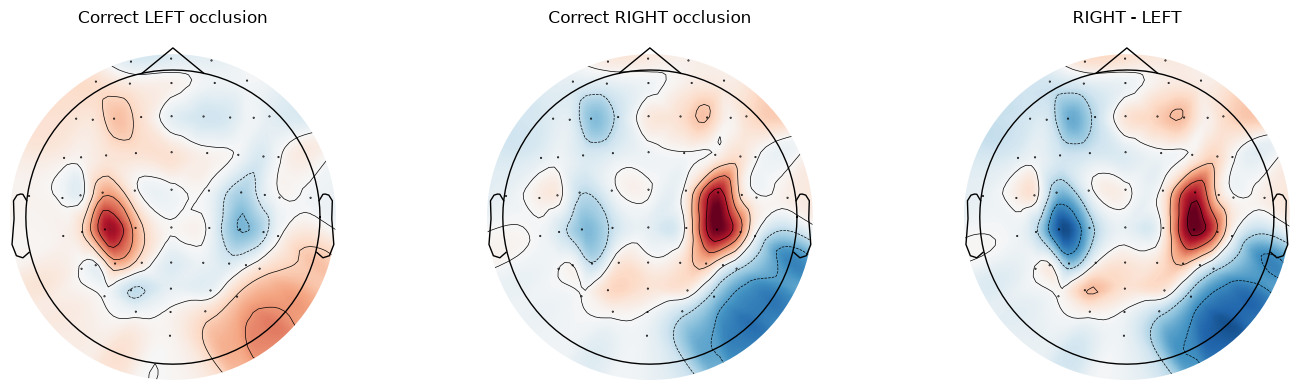

In [91]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

# Shared scale for LEFT and RIGHT maps
common_abs = max(
    np.max(np.abs(mean_left_subject)),
    np.max(np.abs(mean_right_subject))
)

mne.viz.plot_topomap(
    mean_left_subject,
    info,
    axes=axes[0],
    vlim=(-common_abs, common_abs),
    cmap="RdBu_r",
    show=False
)

axes[0].set_title(
    "Correct LEFT occlusion"
)


mne.viz.plot_topomap(
    mean_right_subject,
    info,
    axes=axes[1],
    vlim=(-common_abs, common_abs),
    cmap="RdBu_r",
    show=False
)

axes[1].set_title(
    "Correct RIGHT occlusion"
)


# Difference between RIGHT and LEFT
difference_map = (
    mean_right_subject
    - mean_left_subject
)

diff_abs = np.max(
    np.abs(difference_map)
)

mne.viz.plot_topomap(
    difference_map,
    info,
    axes=axes[2],
    vlim=(-diff_abs, diff_abs),
    cmap="RdBu_r",
    show=False
)

axes[2].set_title(
    "RIGHT - LEFT"
)

plt.tight_layout()

plt.savefig( #Save figure
    ROOT / "results" / "week15_occlusion_topomap.png",
    dpi=200
)

plt.show()

## Compare saliency in trained and untrainged EEGNet

### Load untrained model

In [80]:
random_model = EEGNet(
    n_channels=checkpoint["n_channels"],
    n_classes=checkpoint["n_classes"]
)

random_model = random_model.to(device)
random_model.eval()

EEGNet(
  (block1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 40), stride=(1, 1), padding=same, bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): ELU(alpha=1.0)
    (5): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (6): Dropout(p=0.5, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=same, groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0.5, inplace=False)
  )
  (classifier): Linear(in_features=240, out_feat

### One trial and let trained model predict

In [82]:
trial_index = 0

trial = X_val[trial_index]

trained_result = predict_trial(
    model,
    trial,
    checkpoint,
    device
)

target_class = trained_result["prediction"]

### Calculate both saliency maps

In [83]:
trained_saliency = compute_saliency(
    model,
    trial,
    checkpoint,
    device,
    target_class
)

random_saliency = compute_saliency(
    random_model,
    trial,
    checkpoint,
    device,
    target_class
)

### Average saliency across time

In [84]:
trained_channel_saliency = trained_saliency.mean(
    axis=1
)

random_channel_saliency = random_saliency.mean(
    axis=1
)

### Compare strongest channels

In [85]:
trained_top = np.argsort(
    trained_channel_saliency
)[::-1][:10]

random_top = np.argsort(
    random_channel_saliency
)[::-1][:10]

print("Trained model:")
print(trained_top)

print("Random model:")
print(random_top)

Trained model:
[15 16 19  8 48 12  1  3 31 20]
Random model:
[17 40  9  6 57  7 48 38 23 20]


### Correlation

In [86]:
correlation = np.corrcoef(
    trained_channel_saliency,
    random_channel_saliency
)[0, 1]

print(
    "Correlation:",
    correlation
)

Correlation: -0.13700754276177887


### Find 10 validation trials of even spread

In [87]:
trial_indices = np.linspace(
    0,
    len(X_val) - 1,
    10,
    dtype=int
)

print(trial_indices)

[  0  79 159 239 318 398 478 557 637 717]


### Run correlation for each trial

In [88]:
correlations = []

for trial_index in trial_indices:

    trial = X_val[trial_index]

    trained_result = predict_trial(
        model,
        trial,
        checkpoint,
        device
    )

    target_class = trained_result["prediction"]

    trained_saliency = compute_saliency(
        model,
        trial,
        checkpoint,
        device,
        target_class
    )

    random_saliency = compute_saliency(
        random_model,
        trial,
        checkpoint,
        device,
        target_class
    )

    trained_channels = trained_saliency.mean(axis=1)
    random_channels = random_saliency.mean(axis=1)

    correlation = np.corrcoef(
        trained_channels,
        random_channels
    )[0, 1]

    correlations.append(correlation)

    print(
        trial_index,
        correlation
    )

0 -0.13700754276177887
79 -0.13643844227011034
159 -0.0504477507884358
239 -0.02207611649022603
318 -0.19527772106804192
398 -0.1759657223326789
478 -0.1858699377319999
557 -0.1311956407614466
637 -0.14928830279155958
717 -0.134347570268954


In [89]:
print(
    "Mean correlation:",
    np.mean(correlations)
)

print(
    "Min correlation:",
    np.min(correlations)
)

print(
    "Max correlation:",
    np.max(correlations)
)

Mean correlation: -0.13179147472652322
Min correlation: -0.19527772106804192
Max correlation: -0.02207611649022603


### Test src functions

In [ ]:
from neurosignallab.interpretability import (
    compute_saliency,
    compute_channel_occlusion,
    compute_temporal_occlusion
)

In [90]:
test_saliency = compute_saliency(
    model,
    trial,
    checkpoint,
    device,
    target_class
)

print(
    np.allclose(
        test_saliency,
        trained_saliency
    )
)

True


## Week 15 conclusion

I added interpretability to the frozen Configuration D EEGNet model.

I first used gradient saliency to measure how sensitive the predicted-class logit was to each EEG input value. Saliency showed structured channel sensitivity, but the maps were relatively noisy and similar across some individual trials.

I then used channel occlusion, where one EEG channel was set to zero at a time and the change in the target-class logit was measured. Positive occlusion effects indicate that removing the channel reduced the target output, suggesting that the channel supported that prediction.

Across correctly classified validation trials, subject-balanced averaging showed a reproducible pattern. Correct left-imagery predictions depended most strongly on channels such as CP3 and C3, while correct right-imagery predictions depended most strongly on CP4 and C4.

These results describe electrode dependence rather than causal brain activity. The scalp topomaps are interpolations of channel-level occlusion values and are not source-localization maps.

As a sanity check, I compared gradient saliency from the trained EEGNet with saliency from an identical EEGNet with random weights. Across 10 validation trials, the mean channel-saliency correlation was approximately -0.13, indicating that the learned weights substantially changed the saliency pattern.

The validated interpretability functions were moved into `src/neurosignallab/interpretability.py`, and channel occlusion was added to the Streamlit app so that users can inspect which EEG channels most strongly support an individual prediction.